# 02: Flagging late-delivery risk at purchase time

**Client question (last part):** "...and can we flag at-risk orders early?"

The idea: score every new order the moment it is placed, and let the operations team check the riskiest
10% (confirm stock, push the seller to dispatch, pick a faster carrier, or warn the customer).

**Target:** `is_late` for delivered orders (delivered on a later calendar date than promised).

**Features: only what is known when the order is placed**

| Feature | Why it could matter |
|---|---|
| promised delivery days | the deadline itself: a short promise is easier to miss |
| price (items value), freight value, freight-to-price ratio | expensive freight usually means distance or bulk |
| item count, product weight and volume | bigger orders are harder to ship |
| product category | some products ship slower |
| customer state, seller state, same-state flag | the route |
| purchase month and weekday | peak periods and weekend orders |

Not used, on purpose: anything from the review, the approval or carrier hand-off timestamps, and the actual
delivery date. Those only exist after the order is placed, so using them would be data leakage.

The training code lives in `src/features.py` and `src/train_model.py`. This notebook runs it and explains the results.
Run `dbt build` first.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from src.chart_style import AQUA, BLUE, GREY, TEXT_MUTED, register_template
from src.features import FEATURES, TARGET, load_model_data
from src import train_model as tm

register_template()
# Static PNG output so the charts are visible on GitHub without running the notebook.
pio.renderers.default = "png"
pio.renderers["png"].width = 900
pio.renderers["png"].height = 460

FIGURES = PROJECT_ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)


def show(fig: go.Figure, name: str) -> None:
    """Display a chart and save a copy to reports/figures/."""
    fig.write_image(FIGURES / f"{name}.png", width=900, height=460, scale=2)
    fig.show()


pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## 1. The modelling table

One row per delivered order, sorted by purchase time.

In [2]:
df = load_model_data()
print(f"{len(df):,} delivered orders, {df[TARGET].sum():,} late ({df[TARGET].mean():.2%})")
df[FEATURES + [TARGET]].head()

96,470 delivered orders, 6,534 late (6.77%)


,promised_days,items_value,freight_value,freight_to_price_ratio,item_count,total_weight_g,total_volume_cm3,main_category,customer_state,seller_state,is_same_state,purchase_month,purchase_weekday,is_late
0,19,134.9700,8.4900,0.0629,3,"3,000.0000","12,288.0000",health_beauty,SP,PR,no,9,Thursday,1
1,24,29.9000,15.5600,0.5204,1,300.0000,"4,096.0000",watches_gifts,SP,PR,no,10,Monday,0
2,35,21.9000,17.1900,0.7849,1,400.0000,"4,096.0000",sports_leisure,RS,SP,no,10,Monday,0
3,57,36.4900,17.2400,0.4725,1,767.0000,"4,160.0000",sports_leisure,RS,SP,no,10,Monday,0
4,51,119.9000,13.5600,0.1131,1,"2,050.0000","14,960.0000",furniture_decor,SP,SP,yes,10,Monday,0


## 2. Time-based split

The oldest 80% of orders are used for training and the newest 20% for testing. Inside the training period,
its newest 20% is held out again as a **validation slice**, used to pick model settings and to choose between
the two models. The test period is only scored once, at the end.

**Why not a random split?** In real use, the model is trained on past orders and scores future ones. A random
split mixes the two: the model sees orders from the same week, the same peak and the same carrier problems as
the orders it is tested on. It learns "March 2018 was bad" and then gets credit for predicting March 2018.
That looks good on paper and fails in production, because next month's problems are different. A time-based
split asks the real question: *trained on the past, how well does it do on the future?*

In [3]:
results = tm.run()
train, test = results["train"], results["test"]
fit_part, valid_part = results["fit_part"], results["valid_part"]

split_summary = pd.DataFrame({
    part: {
        "orders": len(d),
        "from": f"{d.purchased_at.min():%Y-%m-%d}",
        "to": f"{d.purchased_at.max():%Y-%m-%d}",
        "late rate": f"{d[TARGET].mean():.2%}",
    }
    for part, d in [("fit (train minus validation)", fit_part), ("validation", valid_part),
                    ("full train", train), ("test", test)]
}).T
split_summary

,orders,from,to,late rate
fit (train minus validation),61740,2016-09-15,2018-03-20,7.82%
validation,15436,2018-03-20,2018-05-26,6.69%
full train,77176,2016-09-15,2018-05-26,7.59%
test,19294,2018-05-26,2018-08-29,3.49%


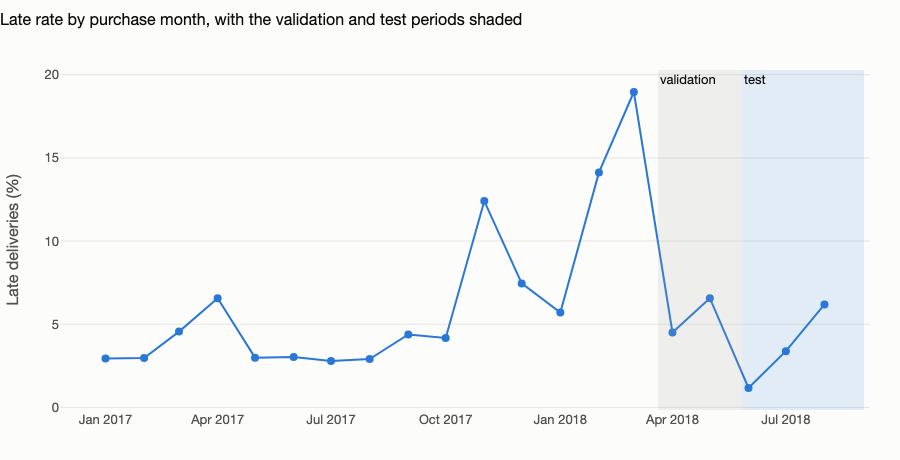

In [4]:
monthly = (
    df[df.purchased_at >= "2017-01-01"]
    .assign(month=lambda d: d.purchased_at.dt.to_period("M").dt.to_timestamp())
    .groupby("month")
    .agg(late_pct=(TARGET, lambda s: 100 * s.mean()), promised_days=("promised_days", "median"))
    .reset_index()
)

fig = go.Figure()
fig.add_vrect(x0=valid_part.purchased_at.min(), x1=valid_part.purchased_at.max(),
              fillcolor=GREY, opacity=0.15, line_width=0,
              annotation_text="validation", annotation_position="top left")
fig.add_vrect(x0=test.purchased_at.min(), x1=test.purchased_at.max() + pd.Timedelta(days=3),
              fillcolor=BLUE, opacity=0.12, line_width=0,
              annotation_text="test", annotation_position="top left")
fig.add_scatter(x=monthly["month"], y=monthly["late_pct"], mode="lines+markers", line_color=BLUE,
                name="late rate", hovertemplate="%{x|%b %Y}: %{y:.1f}%<extra></extra>")
fig.update_layout(title="Late rate by purchase month, with the validation and test periods shaded",
                  yaxis_title="Late deliveries (%)", showlegend=False)
show(fig, "m1_time_split")

The test period (late May to August 2018) is calmer than the training period: 3.49% late vs 7.59%. It contains
no Black Friday and none of the February to March 2018 peak, so it is a hard test. The model has to rank risky
orders in a period that looks quite different from what it learned on.

For comparison, here are the same two models scored on a random 80/20 split:

In [5]:
rand_train, rand_test = train_test_split(df, test_size=0.2, random_state=tm.RANDOM_STATE,
                                         stratify=df[TARGET])
random_split = {}
for name, model in [("logistic_regression", tm.build_logistic_regression()),
                    ("gradient_boosting", tm.build_gradient_boosting(**results["best_params"]))]:
    scores = model.fit(rand_train[FEATURES], rand_train[TARGET]).predict_proba(rand_test[FEATURES])[:, 1]
    random_split[name] = tm.evaluate(rand_test[TARGET], scores)

split_comparison = pd.concat({
    "random split": pd.DataFrame(random_split).T[["roc_auc", "pr_auc", "late_caught_in_top_10pct"]],
    "time split": results["metrics"].loc[["logistic_regression", "gradient_boosting"],
                                         ["roc_auc", "pr_auc", "late_caught_in_top_10pct"]],
}, axis=1)
split_comparison

random split                                 time split  \
                         roc_auc pr_auc late_caught_in_top_10pct    roc_auc   
logistic_regression       0.7626 0.2023                   0.3443     0.7699   
gradient_boosting         0.7845 0.2425                   0.3894     0.6538   

                                                     
                    pr_auc late_caught_in_top_10pct  
logistic_regression 0.1287                   0.3843  
gradient_boosting   0.0644                   0.2122

On a random split, gradient boosting looks like the better model (ROC-AUC 0.78, and 39% of late orders caught
in the top 10%). On the time split it falls to 0.65 and 21%. The random split was rewarding it for memorising
period-specific patterns. If I had used a random split, I would have picked the wrong model and reported numbers
that do not hold up on new orders.

## 3. Something changed in mid-2018: promised delivery times got much shorter

This matters for every result below, so it comes first.

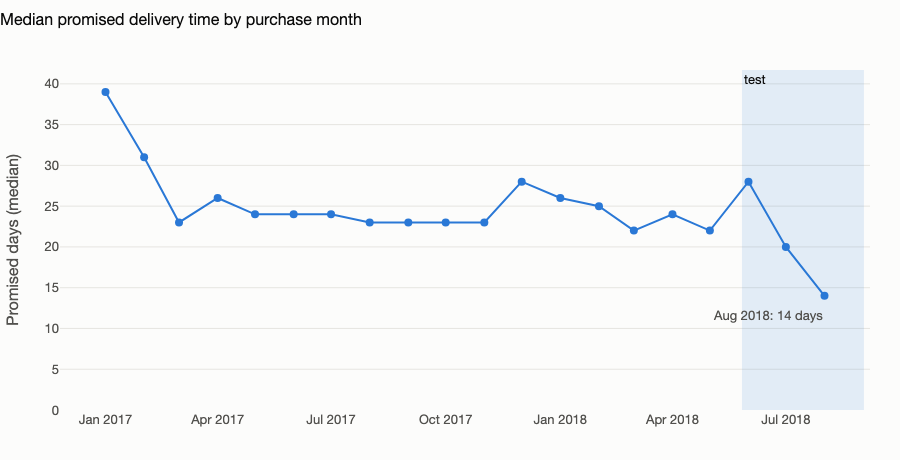

In [6]:
fig = go.Figure()
fig.add_vrect(x0=test.purchased_at.min(), x1=test.purchased_at.max() + pd.Timedelta(days=3),
              fillcolor=BLUE, opacity=0.12, line_width=0,
              annotation_text="test", annotation_position="top left")
fig.add_scatter(x=monthly["month"], y=monthly["promised_days"], mode="lines+markers", line_color=BLUE,
                hovertemplate="%{x|%b %Y}: %{y:.0f} days<extra></extra>")
last = monthly.iloc[-1]
fig.add_annotation(x=last["month"], y=last["promised_days"], text=f"Aug 2018: {last['promised_days']:.0f} days",
                   showarrow=False, xanchor="right", yanchor="top", yshift=-10, font_color=TEXT_MUTED)
fig.update_layout(title="Median promised delivery time by purchase month",
                  yaxis_title="Promised days (median)", yaxis_rangemode="tozero", showlegend=False)
show(fig, "m2_promised_days_by_month")

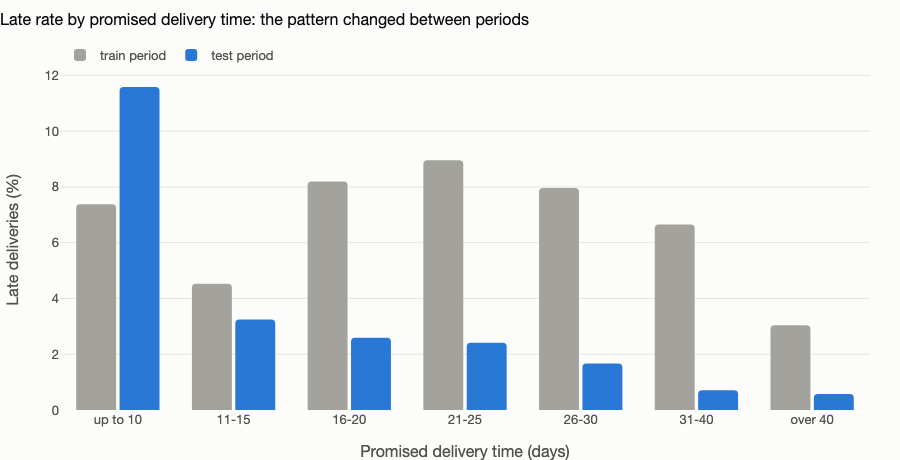

,train,test
promised_days,,
up to 10,7.4000,11.6000
11-15,4.5000,3.2000
16-20,8.2000,2.6000
21-25,9.0000,2.4000
26-30,8.0000,1.7000
31-40,6.7000,0.7000
over 40,3.0000,0.6000


In [7]:
bins = [0, 10, 15, 20, 25, 30, 40, 200]
labels = ["up to 10", "11-15", "16-20", "21-25", "26-30", "31-40", "over 40"]
by_promise = pd.DataFrame({
    name: d.groupby(pd.cut(d.promised_days, bins, labels=labels), observed=True)[TARGET].mean() * 100
    for name, d in [("train", train), ("test", test)]
})

fig = go.Figure()
fig.add_bar(x=by_promise.index, y=by_promise["train"], name="train period", marker_color=GREY,
            hovertemplate="%{x} days: %{y:.1f}% late<extra>train</extra>")
fig.add_bar(x=by_promise.index, y=by_promise["test"], name="test period", marker_color=BLUE,
            hovertemplate="%{x} days: %{y:.1f}% late<extra>test</extra>")
fig.update_layout(title="Late rate by promised delivery time: the pattern changed between periods",
                  xaxis_title="Promised delivery time (days)", yaxis_title="Late deliveries (%)",
                  barmode="group", bargroupgap=0.08)
show(fig, "m3_late_rate_by_promise")
by_promise.round(1)

The median promise fell from 28 days in June 2018 to 14 days in August 2018. In the training period the late
rate barely depends on the promise (between 4.5% and 9% for every bucket except the longest promises, because
the peaks hit every bucket). In
the test period it depends on it strongly: 11.6% of orders promised within 10 days were late, vs 0.6% of orders
promised more than 40 days.

This is **drift**: the relationship between a feature and the target changed over time. It explains why the
simple model wins below. A linear model can only learn "shorter promise means more risk" as a single direction,
and that direction carried over. The tree model learned the exact shape of the training-period pattern, and
that shape did not carry over.

## 4. Models and class imbalance

Only about 1 in 13 training orders is late, so a model could score 92% accuracy by always predicting
"on time". To deal with this:
- Both models use `class_weight="balanced"`, so a missed late order costs as much in training as all
  the on-time orders put together.
- I do not use accuracy at all. ROC-AUC and PR-AUC measure how well the model **ranks** orders, which is what
  the operations team needs. PR-AUC is the stricter one when positives are rare; its random baseline is the
  late rate itself.
- The business metric is the share of all late orders found in the top 10% of risk scores.

One side effect: class weighting pushes the predicted probabilities up, so the output is a **risk score for
ranking**, not a calibrated probability. A score of 0.6 does not mean a 60% chance of being late.

**Models**
1. Logistic regression (baseline): log-scaled numbers, one-hot categories.
2. `HistGradientBoostingClassifier`: native categorical splits, early stopping. 8 settings tried on the validation slice:

In [8]:
results["tuning"][list(tm.GB_GRID) + ["roc_auc", "pr_auc", "late_caught_in_top_10pct"]]

,learning_rate,max_leaf_nodes,min_samples_leaf,roc_auc,pr_auc,late_caught_in_top_10pct
0,0.0500,15,200,0.6515,0.1595,0.2878
1,0.0500,31,200,0.6406,0.1555,0.2791
2,0.1000,15,200,0.6414,0.1552,0.2800
3,0.1000,15,50,0.6385,0.1550,0.2762
4,0.0500,15,50,0.6362,0.1546,0.2839
5,0.1000,31,200,0.6324,0.1531,0.2752
6,0.0500,31,50,0.6353,0.1528,0.2829
7,0.1000,31,50,0.6310,0.1498,0.2684


In [9]:
print("Validation slice (used to choose the model):")
results["validation"]

Validation slice (used to choose the model):


,roc_auc,pr_auc,late_caught_in_top_10pct,late_rate_in_top_10pct,base_late_rate
logistic_regression,0.6816,0.1605,0.3023,0.2021,0.0669
gradient_boosting,0.6515,0.1595,0.2878,0.1924,0.0669
shortest_promise_first,0.5147,0.0659,0.0610,0.0408,0.0669
random_ordering,0.5000,0.0669,0.1000,0.0669,0.0669


In [10]:
print("Selected model:", results["selected_model"])

Selected model: logistic_regression


On the validation slice the logistic regression is slightly better on all three measures, so it is the model
I choose. This decision is made before looking at the test period. The "shortest promise first" row is a
one-line rule (sort orders by promised days, shortest first). It is no better than random on the validation
slice, which is the drift from section 3 again.

## 5. Results on the test period

In [11]:
metrics = results["metrics"]
metrics

,roc_auc,pr_auc,late_caught_in_top_10pct,late_rate_in_top_10pct,base_late_rate
logistic_regression,0.7699,0.1287,0.3843,0.1343,0.0349
gradient_boosting,0.6538,0.0644,0.2122,0.0741,0.0349
shortest_promise_first,0.7503,0.1203,0.4095,0.1431,0.0349
random_ordering,0.5000,0.0349,0.1000,0.0349,0.0349


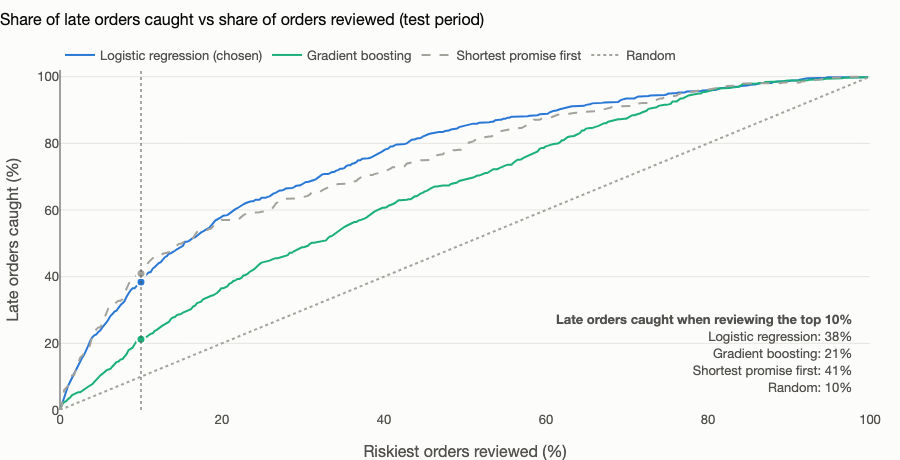

In [12]:
def gains_curve(y_true, scores) -> tuple[np.ndarray, np.ndarray]:
    """Cumulative % of late orders caught as more of the riskiest orders are reviewed."""
    order = np.argsort(-np.asarray(scores), kind="stable")
    caught = np.cumsum(np.asarray(y_true)[order]) / np.sum(y_true)
    reviewed = np.arange(1, len(order) + 1) / len(order)
    return 100 * reviewed, 100 * caught


curves = {
    "Logistic regression (chosen)": (results["scores"]["logistic_regression"], BLUE, "solid"),
    "Gradient boosting": (results["scores"]["gradient_boosting"], AQUA, "solid"),
    "Shortest promise first": (tm.shortest_promise_first(test), GREY, "dash"),
}
fig = go.Figure()
for name, (scores, colour, dash) in curves.items():
    x, y = gains_curve(test[TARGET], scores)
    step = max(1, len(x) // 400)
    fig.add_scatter(x=x[::step], y=y[::step], mode="lines", name=name, line=dict(color=colour, dash=dash),
                    hovertemplate="review %{x:.0f}% of orders: catch %{y:.0f}% of late<extra>" + name + "</extra>")
fig.add_scatter(x=[0, 100], y=[0, 100], mode="lines", name="Random", line=dict(color=GREY, dash="dot"),
                hoverinfo="skip")
fig.add_vline(x=10, line_color=TEXT_MUTED, line_width=1, line_dash="dot")

# Mark where each curve crosses the 10% review line and summarise it in the empty lower-right corner.
at_10 = {
    "Logistic regression": ("logistic_regression", BLUE),
    "Gradient boosting": ("gradient_boosting", AQUA),
    "Shortest promise first": ("shortest_promise_first", GREY),
}
lines = []
for label, (row, colour) in at_10.items():
    caught = 100 * metrics.loc[row, "late_caught_in_top_10pct"]
    fig.add_scatter(x=[10], y=[caught], mode="markers", showlegend=False, hoverinfo="skip",
                    marker=dict(color=colour, size=9, line=dict(color="white", width=2)))
    lines.append(f"{label}: {caught:.0f}%")
lines.append("Random: 10%")
fig.add_annotation(x=98, y=4, xanchor="right", yanchor="bottom", align="right", showarrow=False,
                   text="<b>Late orders caught when reviewing the top 10%</b><br>" + "<br>".join(lines),
                   font_color=TEXT_MUTED)
fig.update_layout(title="Share of late orders caught vs share of orders reviewed (test period)",
                  xaxis_title="Riskiest orders reviewed (%)", yaxis_title="Late orders caught (%)",
                  xaxis_range=[0, 100], yaxis_range=[0, 102])
show(fig, "m4_gains_curve")

In [13]:
n_test = len(test)
n_flagged = int(round(n_test * tm.REVIEW_SHARE))
n_late = int(test[TARGET].sum())
lr_row = metrics.loc["logistic_regression"]
print(f"Test orders: {n_test:,}, late: {n_late:,}")
print(f"Orders the team reviews (top 10%): {n_flagged:,}")
print(f"Late orders among them: {lr_row.late_caught_in_top_10pct * n_late:.0f} "
      f"= {lr_row.late_caught_in_top_10pct:.1%} of all late orders "
      f"({lr_row.late_caught_in_top_10pct / tm.REVIEW_SHARE:.1f}x random)")
print(f"Late rate inside the flagged group: {lr_row.late_rate_in_top_10pct:.1%} "
      f"vs {lr_row.base_late_rate:.1%} overall")

Test orders: 19,294, late: 674
Orders the team reviews (top 10%): 1,929
Late orders among them: 259 = 38.4% of all late orders (3.8x random)
Late rate inside the flagged group: 13.4% vs 3.5% overall


In [14]:
lr_scores = results["scores"]["logistic_regression"]
by_month = (
    test.assign(score=lr_scores, month=test.purchased_at.dt.strftime("%Y-%m"))
    .groupby("month")
    .apply(lambda g: pd.Series({
        "orders": len(g),
        "late_orders": int(g[TARGET].sum()),
        "late_rate": g[TARGET].mean(),
        "roc_auc": roc_auc_score(g[TARGET], g["score"]),
        "late_caught_in_top_10pct": tm.capture_rate(g[TARGET], g["score"]),
    }), include_groups=False)
)
by_month

,orders,late_orders,late_rate,roc_auc,late_caught_in_top_10pct
month,,,,,
2018-05,691.0000,2.0000,0.0029,0.8882,0.5000
2018-06,"6,096.0000",71.0000,0.0116,0.7887,0.3662
2018-07,"6,156.0000",208.0000,0.0338,0.6899,0.3558
2018-08,"6,351.0000",393.0000,0.0619,0.7187,0.2977


**Reading the results**
- The chosen logistic regression has a test ROC-AUC of 0.77 and PR-AUC of 0.13 (random: 0.03).
- **Business metric:** if the team reviews the riskiest 10% of orders (1,929 of 19,294), they find 38.4% of all
  late orders: 259 of 674, or 3.8 times better than picking orders at random. About 1 in 7 flagged orders is
  late, vs 1 in 29 overall.
- Gradient boosting catches 21.2% (ROC-AUC 0.65). It is better than random but clearly worse than the baseline.
- The model holds up in every test month: 30% to 37% of late orders caught in the top 10% for June, July and
  August. (Late May is only a few days with 2 late orders, so ignore its row.)
- **The honest caveat:** on the test period, the one-line "shortest promise first" rule is about as good
  (41% caught, ROC-AUC 0.75). Most of what the model knows comes from the promised delivery time. The model's
  advantage is that it also worked on the validation period, where the rule was no better than random. It is
  the safer choice when you don't know which way the next few months will go, but it does not add much on top
  of the promised date when promises are short.

## 6. What drives the score

Permutation importance: shuffle one feature at a time on the test set and measure how much PR-AUC drops. A big
drop means the model relies on that feature. A drop near zero, or a negative one, means it does not help
on this period. Each feature is shuffled 10 times.

In [15]:
chosen = results["models"][results["selected_model"]]
perm = permutation_importance(chosen, test[FEATURES], test[TARGET], scoring="average_precision",
                              n_repeats=10, random_state=tm.RANDOM_STATE, n_jobs=-1)
importance = (
    pd.DataFrame({"feature": FEATURES, "pr_auc_drop": perm.importances_mean, "std": perm.importances_std})
    .sort_values("pr_auc_drop", ascending=False)
    .reset_index(drop=True)
)
importance

,feature,pr_auc_drop,std
0,promised_days,0.0953,0.0008
1,seller_state,0.0218,0.0029
2,customer_state,0.0183,0.0040
3,item_count,0.0060,0.0009
4,purchase_month,0.0010,0.0014
5,main_category,0.0008,0.0011
6,purchase_weekday,0.0007,0.0003
7,freight_to_price_ratio,0.0006,0.0009
8,items_value,0.0003,0.0013
9,total_weight_g,0.0002,0.0000


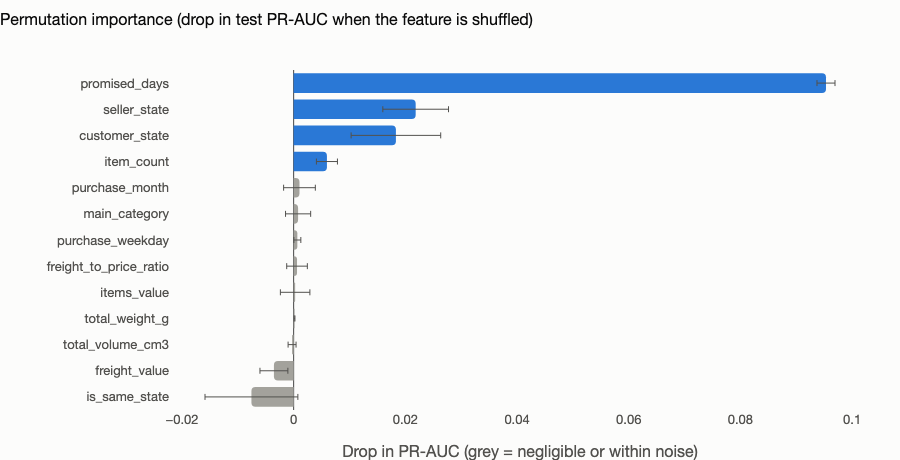

In [16]:
plot_data = importance.iloc[::-1]
# Blue only if the effect is both beyond the shuffle noise (2 standard deviations) and not tiny.
clear = (plot_data["pr_auc_drop"] > 2 * plot_data["std"]) & (plot_data["pr_auc_drop"] >= 0.001)
fig = go.Figure()
fig.add_bar(y=plot_data["feature"], x=plot_data["pr_auc_drop"], orientation="h",
            marker_color=np.where(clear, BLUE, GREY),
            error_x=dict(type="data", array=2 * plot_data["std"], color=TEXT_MUTED, thickness=1, width=3),
            hovertemplate="%{y}: PR-AUC drops by %{x:.4f}<extra></extra>")
fig.update_layout(title="Permutation importance (drop in test PR-AUC when the feature is shuffled)",
                  xaxis_title="Drop in PR-AUC (grey = negligible or within noise)", margin=dict(l=170))
show(fig, "m5_permutation_importance")

Supporting tables for the top drivers, using the test period: actual late rate and the average risk score.

In [17]:
scored_view = test.assign(score=lr_scores)


def driver_table(column: str, min_orders: int = 200) -> pd.DataFrame:
    """Actual late rate and average model score for each value of a feature."""
    return (
        scored_view.groupby(column, observed=True)
        .agg(orders=(TARGET, "size"), late_rate=(TARGET, "mean"), avg_score=("score", "mean"))
        .query("orders >= @min_orders")
        .sort_values("avg_score", ascending=False)
    )


scored_view["promised_bucket"] = pd.cut(scored_view.promised_days, bins, labels=labels)
driver_table("promised_bucket")

,orders,late_rate,avg_score
promised_bucket,,,
up to 10,2901,0.1158,0.5407
11-15,3208,0.0324,0.3600
16-20,3199,0.0259,0.3180
21-25,3363,0.0241,0.2975
26-30,2580,0.0167,0.2728
31-40,2822,0.0071,0.2304
over 40,1221,0.0057,0.1977


In [18]:
driver_table("seller_state")

,orders,late_rate,avg_score
seller_state,,,
MA,225,0.1111,0.6190
SP,13460,0.0383,0.3479
RJ,1034,0.0358,0.3396
MG,1362,0.0140,0.2672
SC,690,0.0333,0.2605
PR,1444,0.0208,0.2543
RS,485,0.0227,0.1886


In [19]:
driver_table("customer_state")

,orders,late_rate,avg_score
customer_state,,,
CE,215,0.0047,0.4826
BA,638,0.0439,0.4823
PE,322,0.0435,0.4782
ES,360,0.0389,0.4266
RJ,2213,0.0312,0.4070
SC,620,0.0161,0.3857
GO,346,0.0260,0.3203
RS,939,0.0192,0.3190
DF,467,0.0278,0.3015


In [20]:
scored_view["items"] = scored_view.item_count.clip(upper=3).astype(str).replace({"3": "3+"})
driver_table("items", min_orders=100)

,orders,late_rate,avg_score
items,,,
1,17462,0.0364,0.3351
2,1402,0.0193,0.2769
3+,430,0.0256,0.2240


In [21]:
coefficients = pd.Series(chosen.named_steps["model"].coef_[0], chosen[:-1].get_feature_names_out())
print("Purchase month coefficients (log-odds, higher = riskier):")
coefficients[coefficients.index.str.startswith("cat__purchase_month")].sort_values().round(2)

Purchase month coefficients (log-odds, higher = riskier):


cat__purchase_month_7    -0.8700
cat__purchase_month_8    -0.7500
cat__purchase_month_6    -0.6200
cat__purchase_month_9    -0.5700
cat__purchase_month_10   -0.5400
cat__purchase_month_5    -0.1800
cat__purchase_month_4    -0.1700
cat__purchase_month_1     0.2100
cat__purchase_month_12    0.5700
cat__purchase_month_11    0.7100
cat__purchase_month_2     0.9100
cat__purchase_month_3     0.9300
dtype: float64

### The top 5 drivers in plain English

1. **Promised delivery time (by far the most important).** The shorter the promise, the higher the risk.
   Orders promised within 10 days were late 11.6% of the time in the test period, vs under 1% for orders
   promised more than 30 days. This is common sense: a tight deadline leaves no slack for a slow seller or
   a carrier delay. It is also something Olist controls directly when it sets the estimated date.
2. **Seller state.** Where the parcel starts matters. Sellers in Maranhão (MA) are the clearest risk: 11.1% of
   their test-period orders were late. São Paulo (SP) sellers score above average too. SP is the national hub,
   so its parcels travel far, and in the training period its long-distance routes (SP to RJ and the Northeast)
   produced the most late orders.
3. **Customer state.** Where the parcel goes matters as well. The model learned from the training period that
   the Northeast (Alagoas, Sergipe, Bahia, Ceará), the North (Roraima, Pará) and, to a lesser degree, Rio de
   Janeiro are risky destinations, and that
   São Paulo, Minas Gerais and Paraná are safe. That pattern was weaker in the test period, which is one
   reason the model is only moderately good.
4. **Number of items.** Orders with 2 or more items are slightly *less* likely to be late (1.9% vs 3.6% for
   single-item orders in the test period). This is a small effect, and my guess is that larger orders tend
   to come from bigger, better organised sellers. The data does not let me confirm that.
5. **Purchase month (weak).** The model learned that November, February and March are high-risk months (Black
   Friday and the early-2018 peak). The test period only covers May to August, so this feature adds almost
   nothing to ranking here; its effect is within noise. It would matter again next November.

Everything else (price, freight, weight, volume, category, weekday) adds little once the promise and the route
are known. Two features have a *negative* importance on the test period, meaning the model would do slightly
better without them: `is_same_state` and `freight_value`. In training, same-state orders were half as likely to
be late (4.3% vs 9.3%). In the test period this reversed (5.1% vs 2.4%). The reason is the new short promises: 34% of same-state test
orders were promised within 10 days, vs 4% in training, and most of those were São Paulo to São Paulo. This is
the same drift problem again.

**How I would explain a single flagged order to a client** (a real order from the test period, ranked 5th of
19,294, and it did arrive late): "This order was promised in 8 days, far shorter than most
orders (the median in this period was 21 days). It ships from São Paulo to Rio de Janeiro, a long route that has produced more late orders than almost
any other. That combination is why it is near the top of today's list."

## 7. Save the scored test set for the dashboard

In [22]:
scored = tm.scored_test_set(test, lr_scores)
scored.to_parquet(tm.SCORES_PATH, index=False)
print(f"wrote {len(scored):,} rows to {tm.SCORES_PATH.relative_to(PROJECT_ROOT)} "
      f"({tm.SCORES_PATH.stat().st_size / 1e6:.1f} MB)")
scored.head()

wrote 19,294 rows to app/data/late_risk_scores.parquet (1.4 MB)


,order_id,purchased_at,customer_state,seller_state,main_category,promised_days,items_value,freight_value,is_late,risk_score,risk_percentile,flagged_top_10pct
0,4d7dc7fe5a388ead18c9355d74c49998,2018-08-21 07:48:58,MA,MA,health_beauty,3,64.9900,9.1500,0,0.9878,1.0000,True
1,38289de96763d9d81470f67583f4b2f0,2018-08-22 11:49:11,MA,MA,health_beauty,5,66.9900,9.1600,1,0.9705,0.9999,True
2,278e7730f7062014d198fbf20451b935,2018-07-30 11:57:40,RJ,SP,toys,3,113.1000,8.2100,0,0.9664,0.9999,True
3,97415fb39aa90a8bfea4424d7bfbc5db,2018-08-19 14:08:32,RJ,MA,health_beauty,12,122.9900,30.1100,0,0.9488,0.9998,True
4,d115642fba3060e4082472bb2801b111,2018-08-02 15:46:16,RJ,SP,bed_bath_table,8,299.0000,45.8900,1,0.9450,0.9998,True


## 8. Honest assessment

**Is the model good?** Moderately. It finds 38% of late orders by reviewing 10% of orders, which is a useful
way to focus a small operations team. It will not catch most late orders, and most flagged orders (6 out of 7)
will arrive on time anyway.

**Why it is not better:**
- The main causes of lateness are not in the data: which carrier was used, how busy it was, warehouse delays,
  weather, strikes and stock-outs. The model only sees the order, the product and the route.
- The biggest spikes (Black Friday 2017, February to March 2018) were operational events that hit all kinds of
  orders at once. The order details cannot predict those. A weekly late-rate monitor (see the findings report)
  is a better tool for them than an order-level model.
- The data drifted: Olist shortened its promised times sharply in mid-2018, which changed how lateness relates
  to the features.
- The test period has a few right-censored orders: some August 2018 orders were still in transit when the data
  was extracted and are not in the test set. Only 47 August orders were still marked as shipped, so the
  effect is small, but if anything the test late rate is slightly understated.

**What would improve it:**
- Seller history features, such as each seller's late rate and dispatch time over the previous 90 days,
  calculated only from orders before the one being scored so there is no leakage.
- Carrier and shipping-method data, if Olist has it.
- Retraining every month and checking the validation slice each time, since the promise policy clearly changes.
- Calibrating the scores (for example with isotonic regression on the validation slice) if the team wants
  real probabilities rather than a ranking.